# Multi frame prediction and saving new annotations in COCO format

### Prediction post-processing and evaluation

1. Generate the pixel-wise prediction (`img_pred`) and save
   `{fnam}_prediction.png`.

2. Label connected foreground regions:
   `new_labels = label(img_pred > 0)`.

3. Using the unexpanded `new_labels`, extract region IDs and geometric
   properties, and assign each region a cell type by majority vote
   over non-background prediction pixels (`df['gray']`, `df['anatomy']).
   Geometric properties are supplementary outputs and are not used
   to calculate segmentation scores.

4. Map the assigned grayscale values back onto `new_labels` and save
   `{fnam}_pred_cleaned.png`.

5. Export the reconstructed mask as `{fnam}_annot_coco.json`.

6. Remap the ground-truth grayscale values and convert both the GT
   and reconstructed prediction to class IDs. Border-touching cells
   are retained in both masks.

7. Calculate IoU, Dice and Accuracy, and save
   `{fnam}_evaluation_scores.csv`.

8. Save the scores for the evaluated image to
   `{fnam}_evaluation_scores.csv`.

`expanded_labels` is generated separately for supplementary
visualisation. It is not used for class assignment, geometric
property extraction, mask reconstruction or score calculation.

In [1]:
import os
import torch
import cv2
import numpy as np
from tqdm import tqdm
from PIL import Image
import matplotlib.pyplot as plt
import time
import itertools
import pandas as pd
import json

from skimage import data, graph
from skimage.filters import threshold_otsu
from skimage.measure import label, regionprops, regionprops_table
from skimage.morphology import closing, square
from skimage.color import label2rgb
from skimage.segmentation import expand_labels

from src.load_mrcnn import get_model, load_checkpoint, predict_multi_frame


### Read prediction model

In [2]:

''' set gpu to be used '''
GPU_ID = 0
DEVICE = torch.device(f'cuda:{GPU_ID}' if torch.cuda.is_available() else 'cpu')
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 5e-4


############################

image_size = 512  # choice is 256 or 512
IMAGE_SIZE = [image_size, image_size] 

sp = "hakdac"  ############# change species

# test image to read
TEST_DIR = f'dataset/{sp}/png_'+str(image_size)+'/image/test'

# load mrcnn model 
MODEL_FILE = f"{image_size}_thin_{sp}_700_epoch.tar" ############# change model
dir_inferresult= f"{image_size}_thin_singlesp_700_epoch.tar"

base_dir = './inference_results_recheck20261011'
sub_dir = os.path.join(base_dir, f'{image_size}_thin_singlespecies_700_epoch') ##############Change here when using thin_dataset


# Image to be predict
#data_img = 'dataset/performance_check/img/burspi1_01_img.png'

sp_to_filename = {
    "acapod": "acapod2_01_img.png",
    "alllit": "alllit2_01_img.png",
    "burspi": "burspi1_01_img.png",
    "euclon": "euclon1_01_img.png",
    "exostr": "exostr8_01_img.png",
    "hakdac": "hakdac2_01_img.png"
}

filename = sp_to_filename[sp]
input_dir = 'dataset/performance_check/image'
data_img = os.path.join('dataset/performance_check/image', filename)


############################


model = get_model()
model.to(DEVICE)   
optimizer = torch.optim.AdamW(params=model.parameters(),
                                  lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY
                                  )
load_checkpoint(torch.load(os.path.join('./model',MODEL_FILE),weights_only=True), model, optimizer, LEARNING_RATE)

model.eval()

print("GPU:{}".format(GPU_ID)+' will be used for calculation')



=> Loading checkpoint
GPU:0 will be used for calculation


## Prediction

In [3]:
model.train(False)

img_num = 1

testfilename = [fl for fl in os.listdir(TEST_DIR) if fl.endswith('.png')]
print('You have ', str(len(testfilename)-1), \
      ' test images, and you selected image No. ', str(img_num))
img0 = Image.open(os.path.join(TEST_DIR,testfilename[img_num])).convert('RGB')


You have  7  test images, and you selected image No.  1


Check model using test image !

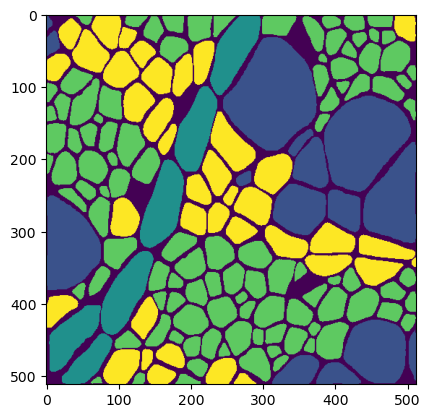

In [4]:
img = cv2.imread(os.path.join(TEST_DIR,testfilename[img_num]))
res2 = predict_multi_frame(model, img, IMAGE_SIZE, 0.7, 0.7, DEVICE)
plt.imshow(res2)
plt.show()

Predictions are generated from overlapping patches. Only the central
384 × 384 pixels of each 512 × 512 patch, or 192 × 192 pixels of each, 256 × 256 patch, are retained and stitched together to reconstruct the full image.

16it [00:02,  6.10it/s]


GPU time =  2.6240482330322266  sec


(-0.5, 1535.5, 1535.5, -0.5)

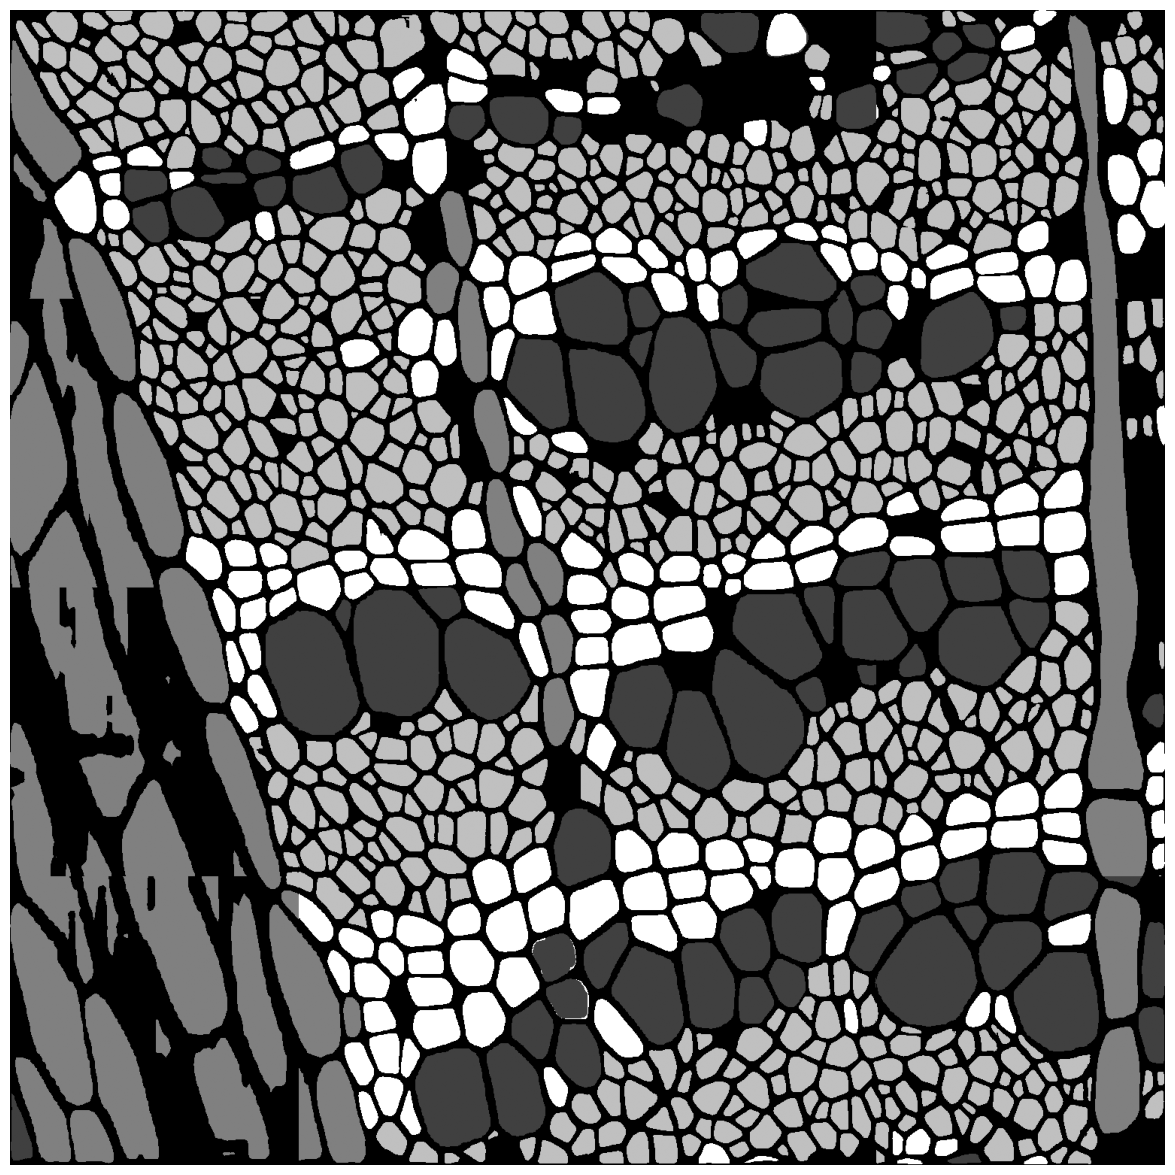

In [5]:
if image_size == 512:
    pad = 64
    sz = 384
    l = list(range(4))
elif image_size == 256:
    pad = 32
    sz = 192
    l = list(range(8))
else:
    raise ValueError(f"Unsupported image_size: {image_size}")


img_in = cv2.imread(data_img)
img_padded = cv2.copyMakeBorder(img_in, pad, pad, pad, pad, cv2.BORDER_CONSTANT, (0,0,0))
height, width, _ = img_padded.shape

img_pred = np.zeros_like(img_in[:,:,0])
start = time.time()


for i,j in tqdm(itertools.product(l, l)): 
    img_patch = img_padded[sz*i:sz*i+image_size, sz*j:sz*j+image_size, :]
    res2 = predict_multi_frame(model, img_patch, IMAGE_SIZE, 0.7, 0.9, DEVICE)  
    res2 = res2[pad:pad+sz,pad:pad+sz]
    img_pred[sz*i:sz*i+sz,sz*j:sz*j+sz]=res2
end = time.time()


fnam = os.path.splitext(os.path.basename(data_img))[0]
os.makedirs(sub_dir, exist_ok=True)

os.makedirs(os.path.join(sub_dir, 'prediction_raw'),exist_ok=True)

integ_img =  Image.fromarray(img_pred)
integ_img.save(
    os.path.join(sub_dir, 'prediction_raw', f'{fnam}_prediction.png')
)

print( 'GPU time = ', end - start, ' sec')
fig = plt.subplots(figsize=(15,15))
plt.imshow(img_pred,cmap='gray')
plt.axis('off')


## Relabelling the reconstructed prediction image

Connected foreground regions are labelled using
`label(img_pred > 0)`. Regions touching the image border are retained.

The original, unexpanded labels (`new_labels`) are used for
supplementary geometric property extraction, majority-vote cell-type
assignment and prediction mask reconstruction.

Expanded labels (`expanded_labels`) are generated only for
supplementary visualisation. No border removal or graph construction
is performed in this notebook.


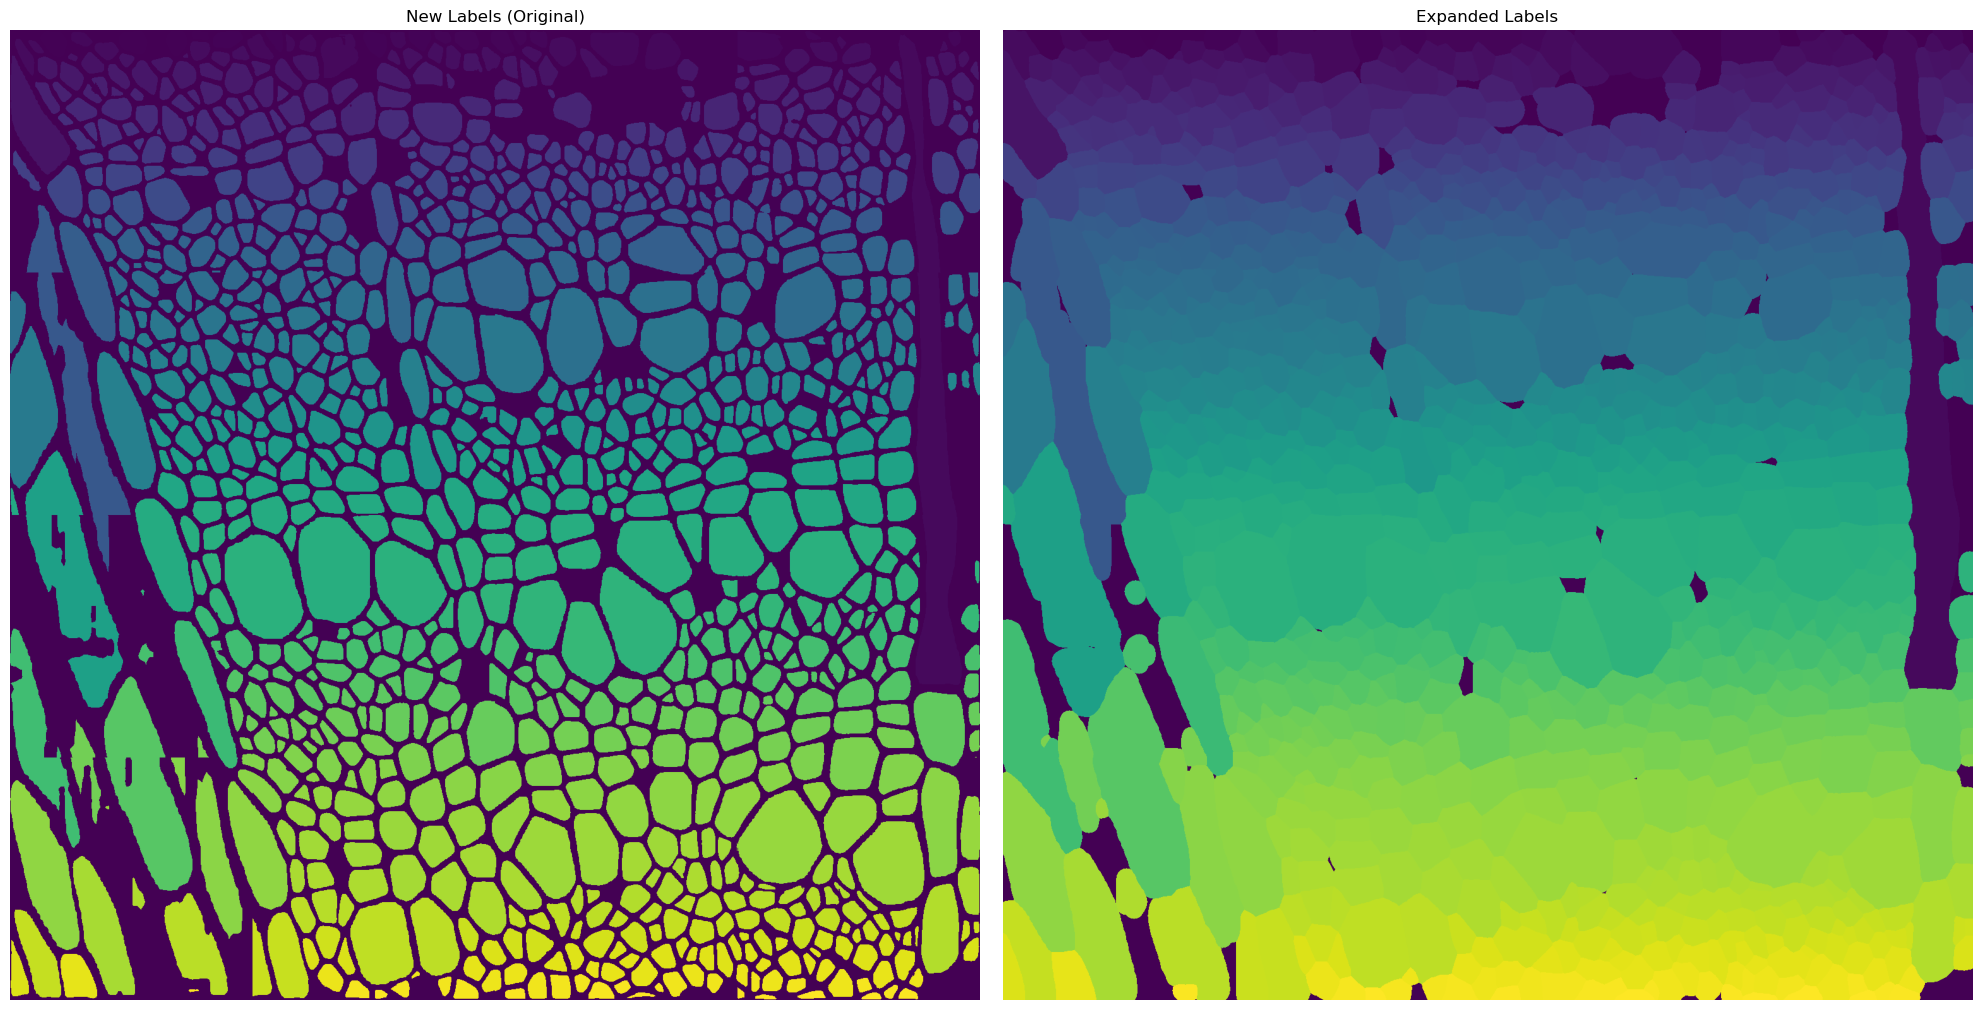

In [6]:
new_labels = label(img_pred > 0)
expanded_labels = expand_labels(new_labels, distance=15)

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

axes[0].imshow(new_labels)
axes[0].set_title("New Labels (Original)")
axes[0].axis("off")

axes[1].imshow(expanded_labels)
axes[1].set_title("Expanded Labels")
axes[1].axis("off")

plt.tight_layout()
plt.show()


Predictive maps of cell types were labelled and the morphological elements were obtained from them using the reagionalprops function of SKIMAGE, and then stored in the panda data.

In [7]:
##これより上チェックずみ

In [8]:
props = regionprops_table(
    new_labels,
    properties=('label','centroid','bbox', 'orientation', 'axis_major_length', 'axis_minor_length', 'area'),
)
df = pd.DataFrame(props)


In [9]:
# Assign each unexpanded region its majority non-background class.
# These assignments are used for prediction mask reconstruction.

def get_gray(p):
    output = img_pred[new_labels == p]
    out = output[np.isin(output, [64, 128, 192, 255])]
    if len(out) == 0:
        return 0
    return np.argmax(np.bincount(out))

t1 = time.time()
label_list = df['label'].to_numpy()
df['gray'] = [get_gray(lbl) for lbl in label_list]
t2 = time.time()
print(f"{t2 - t1:.2f} sec")

0.82 sec


Summary of colours and grey levels for cell types.

link-table

| cell_type | 'stuff' | 'vessel'             | 'ray'                     | 'fiber'                    | 'parenchyma'        |
| --------- | ------- | -------------------- | ------------------------- | -------------------------- | ------------------- |
| color     | (0,0,0) | （1,159/255,155/255) | (144/255,229/255,161/255) | (161/255,201/255,244/255), | (1,180/255,130/255) |
| gray      | 0       | 64                   | 128                       | 192                        | 255                 |

In [10]:
# definition of color graylevel celltype 
color = [(0,0,0),(1,159/255,155/255),(144/255,229/255,161/255),\
              (161/255,201/255,244/255),(1,180/255,130/255)]
cell_type = ['stuff','vessel','ray','fiber','parenchyma']
gray = [  0,  64, 128, 192, 255]

gr_cell_dict = dict(zip(gray,cell_type))
gr_c_dict = dict(zip(gray,color))
cell_gr_dict = dict(zip(cell_type,gray))
cell_c_dict = dict(zip(cell_type,color))

In [11]:
cell_types =[]
colors = []
for i in tqdm(range(len(df))):
    cell_types.append(gr_cell_dict[df['gray'].values[i]])
    colors.append(gr_c_dict[df['gray'].values[i]])
df['color'] = colors
df['anatomy'] = cell_types


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 1064/1064 [00:00<00:00, 194006.85it/s]


In [12]:

import copy
#set function
new_labels_copy=copy.deepcopy(new_labels).flatten()
new_annotation=np.zeros((len(new_labels_copy)))

t1 = time.time()
replace_func = {label: new for new , label in zip(list(df['gray'].values), list(df['label'].values))}

#replace label values to anatomical values
replace_result=np.asarray(list(map(replace_func.get, new_labels_copy.flatten())))
result_index=np.where(replace_result!=None)[0]

#project the result to zero map
new_annotation[result_index]=replace_result[result_index]
t2 = time.time()
print(str(t2-t1)+" sec")

0.6603608131408691 sec


Check new labels 

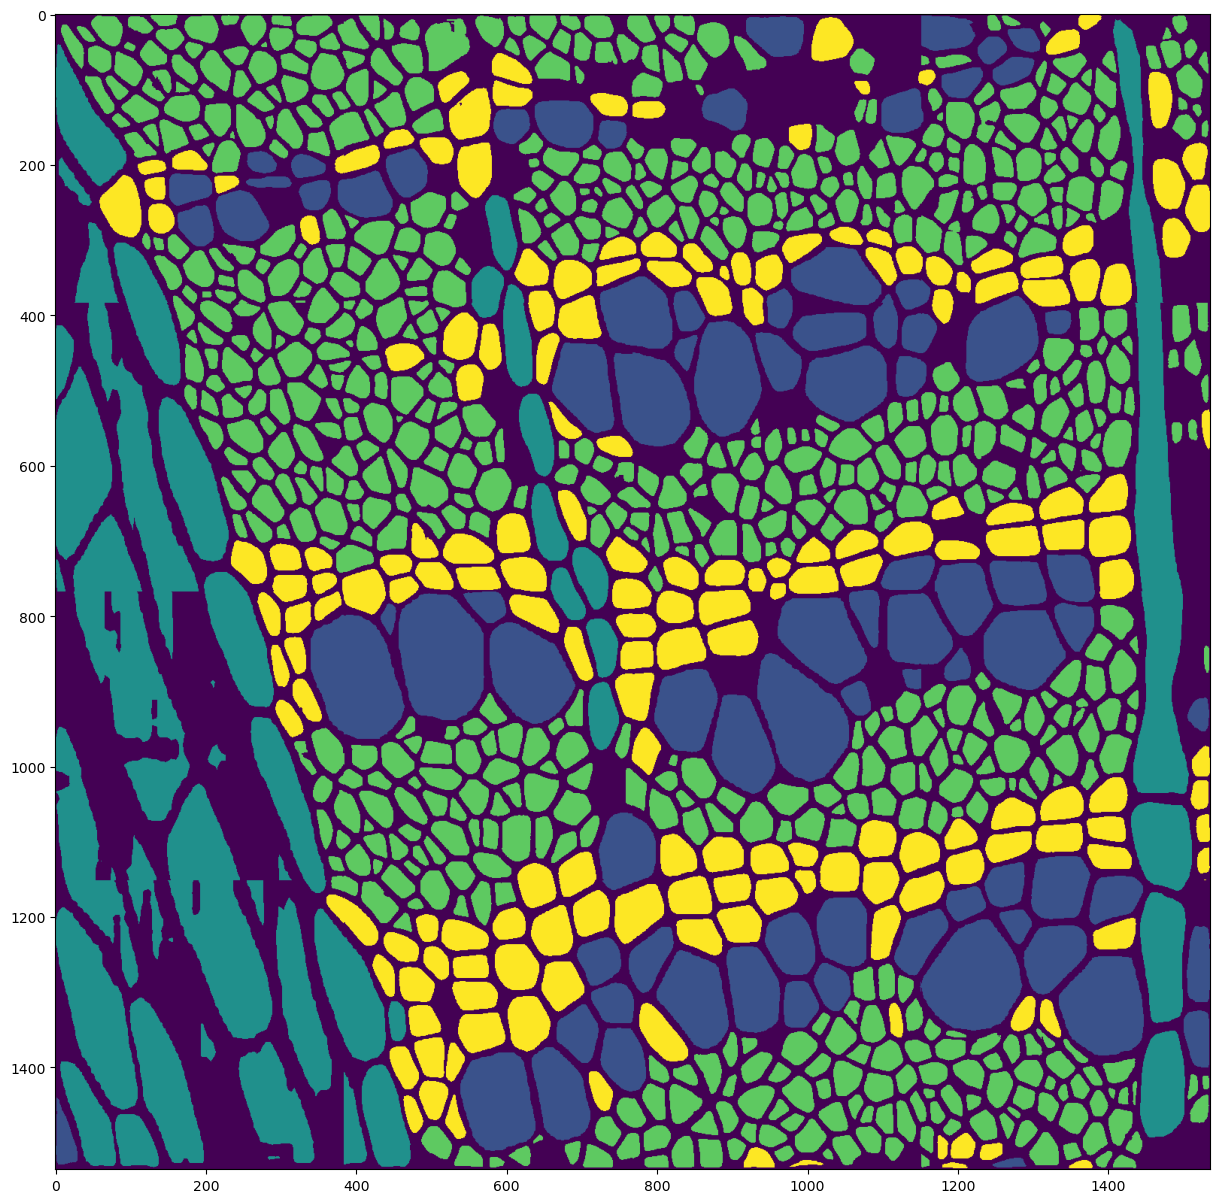

In [13]:
newly_annotated_img = new_annotation.reshape((new_labels.shape))

fig, ax = plt.subplots(figsize=(15,15))
ax.imshow(newly_annotated_img)
nai = Image.fromarray(newly_annotated_img.astype('uint8'))
os.makedirs(os.path.join(sub_dir, 'prediction_cleaned'), exist_ok=True)
nai.save(os.path.join(sub_dir, 'prediction_cleaned',fnam+'_pred_cleaned.png'))
plt.show()

In [14]:
newly_annotated_img.min()

0.0

In [15]:
from src.create_annotations import *

# original 2560 x 2560 image 
#data_img = 'dataset/original/Alllit_test_original.png'
#data_img = 'dataset/original/kusunoki.png'


# Label ids of the dataset
category_ids = {
    "stuff" : 0,
    "vessel": 1,
    "ray": 2,
    "fiber": 3,
    "parenchyma": 4
}

# Define which colors match which categories in the images
category_colors = {
    "(0, 0, 0)" : 0, # stuff
    "(64, 64, 64)": 1, # vessel
    "(128, 128, 128)": 2, # ray
    "(192, 192, 192)": 3, # fiber
    "(255, 255, 255)": 4 # parenchyma
}
"""
# Label ids of the dataset
category_ids = {
    "stuff" : 0,
    "unknown": 1,
}

# Define which colors match which categories in the images
category_colors = {
    "(0, 0, 0)" : 0, # stuff
    "(64, 64, 64)": 1 # unknown
}
"""

'\n# Label ids of the dataset\ncategory_ids = {\n    "stuff" : 0,\n    "unknown": 1,\n}\n\n# Define which colors match which categories in the images\ncategory_colors = {\n    "(0, 0, 0)" : 0, # stuff\n    "(64, 64, 64)": 1 # unknown\n}\n'

In [16]:
multipolygon_ids = []

if __name__ == "__main__":
    coco_format = get_coco_json_format()
    
    coco_format["info"] = info()
    coco_format["categories"] = create_category_annotation(category_ids)
    
    coco_format["images"], coco_format["annotations"], annotation_cnt = \
        singleshot_annotations_info(newly_annotated_img, data_img, category_ids, category_colors, multipolygon_ids)

    json_path = os.path.join(sub_dir,'prediction_cleaned_json', f"{fnam}_annot_coco.json")
    os.makedirs(os.path.join(sub_dir,'prediction_cleaned_json'), exist_ok=True)
    with open(json_path, "w") as outfile:
        json.dump(coco_format, outfile)

    print(f"Created {annotation_cnt} annotations and saved to: {json_path}")


Created 1065 annotations and saved to: ./inference_results_recheck20261011/512_thin_singlespecies_700_epoch/prediction_cleaned_json/hakdac2_01_img_annot_coco.json


***

# Validation


1. Load the ground-truth mask in grayscale.

2. Remap its grayscale values using `gt_remap_dict` and
   `remap_gt_gray` to match the prediction labels.

3. Convert the ground-truth mask to class IDs (0–4) using
   `normalize_mask`.

4. Load the reconstructed prediction mask (`*_pred_cleaned.png`)
   and convert it to class IDs using the same mapping.

5. Retain cells touching the image border in both masks.

6. Calculate:
   - Per-class IoU and Dice for the four non-background classes,
     together with their unweighted means.
   - Accuracy over pixels where the ground-truth class is non-background.

7. Display the input image, ground-truth mask, prediction mask
   and calculated scores, and save the comparison figure.

8. Save the scores for all evaluated images to `evaluation_scores.csv`.

In [17]:
label_mapping = {0: 0, 64: 1, 128: 2, 192: 3, 255: 4}
num_classes = len(label_mapping)
ignore_class = 0


def normalize_mask(mask):
    return np.vectorize(label_mapping.get)(mask)

def remap_gt_gray(mask, remap_dict):
    remapped = np.copy(mask)
    for src, dst in remap_dict.items():
        remapped[mask == src] = dst
    return remapped

def compute_iou(gt, pred, num_classes, ignore_class=None):
    iou_list = []
    for cls in range(num_classes):
        if cls == ignore_class:
            continue
        gt_cls = (gt == cls)
        pred_cls = (pred == cls)
        intersection = np.logical_and(gt_cls, pred_cls).sum()
        union = np.logical_or(gt_cls, pred_cls).sum()
        if union == 0:
            continue
        iou_list.append(intersection / union)
    return np.mean(iou_list), iou_list

def compute_dice(gt, pred, num_classes, ignore_class=None):
    dice_list = []
    for cls in range(num_classes):
        if cls == ignore_class:
            continue
        gt_cls = (gt == cls)
        pred_cls = (pred == cls)
        tp = np.logical_and(gt_cls, pred_cls).sum()
        denom = gt_cls.sum() + pred_cls.sum()
        if denom == 0:
            continue
        dice_list.append(2 * tp / denom)
    return np.mean(dice_list), dice_list

def compute_accuracy(gt, pred, ignore_class=None):
    if ignore_class is None:
        return (gt == pred).sum() / gt.size
    mask = gt != ignore_class
    return (gt[mask] == pred[mask]).sum() / mask.sum()


In [ ]:
id_to_classname = {v: k for k, v in category_ids.items()}

# define directories
gt_dir = 'dataset/performance_check/mask'
score_dir = os.path.join(sub_dir, 'scores')
vis_dir = os.path.join(sub_dir, 'visual_comparison')
os.makedirs(score_dir, exist_ok=True)
os.makedirs(vis_dir, exist_ok=True)

score_records = []

# Main loop
fnam = os.path.splitext(filename)[0]
fnam_short = fnam[:-4]

input_dir = 'dataset/performance_check/image'
img_path = os.path.join(input_dir, filename)
gt_path = os.path.join(gt_dir, fnam_short + "_msk.png")
pred_dir = os.path.join(sub_dir, 'prediction_cleaned')
pred_path = os.path.join(pred_dir, fnam + "_pred_cleaned.png")

# Load the input image and ground-truth mask
img = np.array(Image.open(img_path).convert("RGB"))
gt_raw = np.array(Image.open(gt_path).convert("L"))
pred_raw = np.array(Image.open(pred_path).convert("L"))

# Process the ground-truth mask (remapping + normalisation)
gt_remap_dict = {0: 64, 64: 128, 128: 192, 192: 255, 255: 0}
gt_remapped = remap_gt_gray(gt_raw, gt_remap_dict)
gt_norm = normalize_mask(gt_remapped)

# Normalize prediction
pred_norm = normalize_mask(pred_raw)

# score calculation
mean_iou, per_class_iou = compute_iou(gt_norm, pred_norm, num_classes, ignore_class)
mean_dice, per_class_dice = compute_dice(gt_norm, pred_norm, num_classes, ignore_class)
acc = compute_accuracy(gt_norm, pred_norm, ignore_class)

# show plots
fig, axes = plt.subplots(1, 4, figsize=(20, 6))
axes[0].imshow(img)
axes[0].set_title('Input Image')
axes[1].imshow(gt_norm, cmap='gray')
axes[1].set_title('GT Mask')
axes[2].imshow(pred_norm, cmap='gray')
axes[2].set_title('Predicted Mask')

text = f"Mean IoU : {mean_iou:.4f}\nMean Dice: {mean_dice:.4f}\nAccuracy : {acc:.4f}\n"
for cls_id in range(num_classes):
    if cls_id == ignore_class:
        continue
    cls_name = id_to_classname.get(cls_id, f"Class {cls_id}")
    text += f"\n{cls_name} IoU : {per_class_iou[cls_id - 1]:.4f}"
    text += f"\n{cls_name} Dice: {per_class_dice[cls_id - 1]:.4f}"
axes[3].axis('off')
axes[3].text(0, 0.5, text, fontsize=12, va='center')

plt.tight_layout()
fig.savefig(os.path.join(vis_dir, f"{fnam}_comparison.png"), dpi=300)
plt.show()
plt.close(fig)

# save scores as CSV
record = {
    "filename": fnam,
    "mean_iou": mean_iou,
    "mean_dice": mean_dice,
    "accuracy": acc,
}
for cls_id in range(num_classes):
    if cls_id == ignore_class:
        continue
    cls_name = id_to_classname.get(cls_id, f"class{cls_id}")
    record[f"{cls_name}_iou"] = per_class_iou[cls_id - 1]
    record[f"{cls_name}_dice"] = per_class_dice[cls_id - 1]
score_records.append(record)

df_scores = pd.DataFrame(score_records)
df_scores.to_csv(os.path.join(score_dir, f"{fnam}_evaluation_scores.csv"), index=False)
